# NYC access equity

## Goal

Reproduce the displayed results from distributed local inputs, without downloading data. Run every cell in order. Numerical statements are computed in the result cells; none are hard-coded.

## Setup

Use the project's Python environment. Start Jupyter inside this repository or set `ECONHACK_REPO` explicitly. The first cell runs `python -m econhack.cli verify` before reading data. The CLI checks source and processed manifests; tables and PNGs receive separate byte-hash receipts below. No acquisition functions or model `run()` entrypoints are called.

In [1]:
import hashlib
import importlib
import inspect
import io
import json
import os
from pathlib import Path
import subprocess
import sys

def find_repository():
    explicit = os.environ.get("ECONHACK_REPO")
    candidates = [Path(explicit).expanduser().resolve()] if explicit else [Path.cwd().resolve(), *Path.cwd().resolve().parents]
    for candidate in candidates:
        if (candidate / "src/econhack/cli.py").is_file() and (candidate / "pyproject.toml").is_file():
            return candidate
    raise FileNotFoundError("Open this notebook inside the repository, or set ECONHACK_REPO to its root.")

ROOT = find_repository()
os.environ["ECONHACK_OFFLINE"] = "1"
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache/matplotlib"))
sys.path.insert(0, str(ROOT / "src"))
environment = os.environ.copy()
environment["PYTHONPATH"] = str(ROOT / "src") + os.pathsep + environment.get("PYTHONPATH", "")
verification = subprocess.run(
    [sys.executable, "-m", "econhack.cli", "verify"], cwd=ROOT, env=environment,
    capture_output=True, text=True, check=True,
)
print(verification.stdout.strip())
print(f"Repository: {ROOT.name}\nPython: {sys.version.split()[0]}\nMode: local files only")

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Code, Image, Markdown, display

pd.set_option("display.max_columns", 16)
pd.set_option("display.max_rows", 30)
pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.figsize": (10, 5), "font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.prop_cycle": plt.cycler(color=["#176b87", "#b85c38"])})
PROCESSED = ROOT / "data/processed"
TABLES = ROOT / "outputs/tables"
FIGURES = ROOT / "outputs/figures"
input_receipts = []
processed_manifest = json.loads((ROOT / "data/processed_manifest.json").read_text())

def local_file(relative):
    path = (ROOT / relative).resolve()
    if ROOT not in path.parents or not path.is_file():
        raise FileNotFoundError(f"Required local input missing: {relative}. Run the project pipeline and snapshot first.")
    return path

def receipt(path):
    relative = str(path.relative_to(ROOT))
    input_receipts.append({"path": relative, "sha256": hashlib.sha256(path.read_bytes()).hexdigest()})

def read_csv(relative, **kwargs):
    path = local_file(relative)
    if str(path.relative_to(ROOT)).startswith("data/processed/") and str(path.relative_to(ROOT)) not in processed_manifest:
        raise ValueError(f"Processed input is not in the verified manifest: {relative}. Run cli snapshot first.")
    receipt(path)
    return pd.read_csv(path, **kwargs)

def read_json(relative):
    path = local_file(relative)
    receipt(path)
    return json.loads(path.read_text())

def show_png(name, required=True):
    path = FIGURES / f"{name}.png"
    if not path.is_file() and not required:
        display(Markdown(f"Figure `{name}.png` was not produced; consult the model status and estimability table."))
        return
    path = local_file(str(path.relative_to(ROOT)))
    receipt(path)
    display(Image(data=path.read_bytes(), format="png", embed=True, width=1000))

def show_figure(figure):
    buffer = io.BytesIO()
    figure.savefig(buffer, format="png", dpi=140, bbox_inches="tight")
    display(Image(data=buffer.getvalue(), format="png", embed=True, width=1000))

def show_source(module_name, names):
    module = importlib.import_module(module_name)
    display(Markdown(f"Source: `src/{module_name.replace('.', '/')}.py`. Functions below are displayed, not invoked."))
    for name in names:
        display(Code(inspect.getsource(getattr(module, name)), language="python"))

def show_status(name):
    statuses = read_json("outputs/model_status.json")
    display(pd.DataFrame([{key: value for key, value in statuses.get(name, {"status": "not_run"}).items()
                           if key in {"status", "reason", "n", "updated_utc", "formula", "input_mode"}}]))

Verified 38 source/extract hashes; 0 large source files omitted from distribution.
Repository: econhackathon2026
Python: 3.13.7
Mode: local files only


## Context and methods

Unit: NYC census tract. Facility counts use spherical straight-line distance from the Census tract internal point to selected facilities, with an 800 m main radius and 400/1200 m sensitivities. The model is `log1p(nearby_800m) ~ log(income) + poverty_pct + youth_pct + older_pct + log1p(population_density) + C(borough)`, with HC3 covariance. The sample has population ≥100 and complete model variables. ACS 2019–2023 estimates are joined to the current facility snapshot. See `docs/models/nyc_equity.md`.

### Load tract inputs and verify transformations

In [2]:
from econhack.nyc import nearby_counts
access = read_csv("data/processed/nyc_access.csv", dtype={"geoid": str, "county": str})
facilities = read_csv("data/processed/nyc_selected_facilities.csv", dtype={"geoid": str, "county": str})
assert not access.geoid.duplicated().any()
np.testing.assert_allclose(np.log1p(access.nearby_800m), access.log_access)
np.testing.assert_array_equal(nearby_counts(access, facilities, 800), access.nearby_800m)
predictors = ["log_access", "log_income", "poverty_pct", "youth_pct", "older_pct", "log_density"]
sample = access.loc[access.population.ge(100)].replace([np.inf, -np.inf], np.nan).dropna(subset=predictors).copy()
display(sample[["geoid", "borough", "population", "income", "nearby_800m", "poverty_pct"]].head(12))
print(f"Model sample: {len(sample):,} of {len(access):,} tracts; {len(facilities):,} selected facility records.")
show_status("nyc_equity")

,geoid,borough,population,income,nearby_800m,poverty_pct
1,36005000200,Bronx,5177,121171.0,2,14.0815
2,36005000400,Bronx,6481,98242.0,3,4.8912
3,36005001600,Bronx,6011,42957.0,7,18.1281
4,36005001901,Bronx,2401,67361.0,16,30.4674
5,36005001902,Bronx,1979,76429.0,8,35.3515
8,36005002001,Bronx,4300,23208.0,7,49.9070
9,36005002002,Bronx,3689,18029.0,8,47.4971
10,36005002300,Bronx,4527,18750.0,13,48.0999
12,36005002500,Bronx,5460,27207.0,15,46.3982
13,36005002701,Bronx,2830,18788.0,10,57.0413


Model sample: 2,190 of 2,327 tracts; 1,541 selected facility records.


,status,reason,updated_utc,n,formula
0,estimated,Exploratory tract association; HC3 intervals d...,2026-10-20T04:56:11.493237+00:00,2190,log_access ~ log_income + poverty_pct + youth_...


### Tidy model results and sensitivity

In [3]:
coefficients = read_csv("outputs/tables/nyc_equity_coefficients.csv")
assert not coefficients.term.duplicated().any()
display(coefficients)
quintiles = read_csv("outputs/tables/nyc_equity_income_quintiles.csv")
display(quintiles)
display(read_csv("outputs/tables/nyc_equity_radius_sensitivity.csv"))

,term,coefficient,std_error,p_value,ci_lower,ci_upper
0,Intercept,-0.1743,0.5451,7.4919e-01,-1.2425,0.8940
1,C(borough)[T.Brooklyn],-0.0500,0.0368,1.7403e-01,-0.1221,0.0221
2,C(borough)[T.Manhattan],0.3883,0.0452,8.3084e-18,0.2997,0.4768
3,C(borough)[T.Queens],-0.2730,0.0392,3.2782e-12,-0.3499,-0.1962
4,C(borough)[T.Staten Island],-0.6073,0.0645,4.6601e-21,-0.7337,-0.4809
5,log_income,-0.0691,0.0378,6.7878e-02,-0.1432,0.0051
6,poverty_pct,0.0125,0.0016,9.8703e-16,0.0094,0.0155
7,youth_pct,-0.0057,0.0019,3.4571e-03,-0.0095,-0.0019
8,older_pct,-0.0117,0.0016,3.1602e-13,-0.0148,-0.0085
9,log_density,0.2630,0.0196,4.9216e-41,0.2246,0.3014


,income_quintile,tracts,median_nearby,mean_nearby
0,Lowest,438,8,9.3242
1,Q2,438,5,5.7123
2,Q3,438,4,4.5639
3,Q4,438,3,4.1027
4,Highest,438,5,5.8105


,radius_m,term,coefficient,ci_lower,ci_upper
0,400,log_income,-0.1268,-0.2073,-0.0462
1,400,poverty_pct,0.0089,0.0055,0.0123
2,400,youth_pct,-0.0052,-0.0095,-0.0008
3,400,older_pct,-0.0067,-0.0100,-0.0034
4,400,log_density,0.1631,0.1258,0.2004
5,800,log_income,-0.0691,-0.1432,0.0051
6,800,poverty_pct,0.0125,0.0094,0.0155
7,800,youth_pct,-0.0057,-0.0095,-0.0019
8,800,older_pct,-0.0117,-0.0148,-0.0085
9,800,log_density,0.2630,0.2246,0.3014


### Recreate the core plot with native Matplotlib

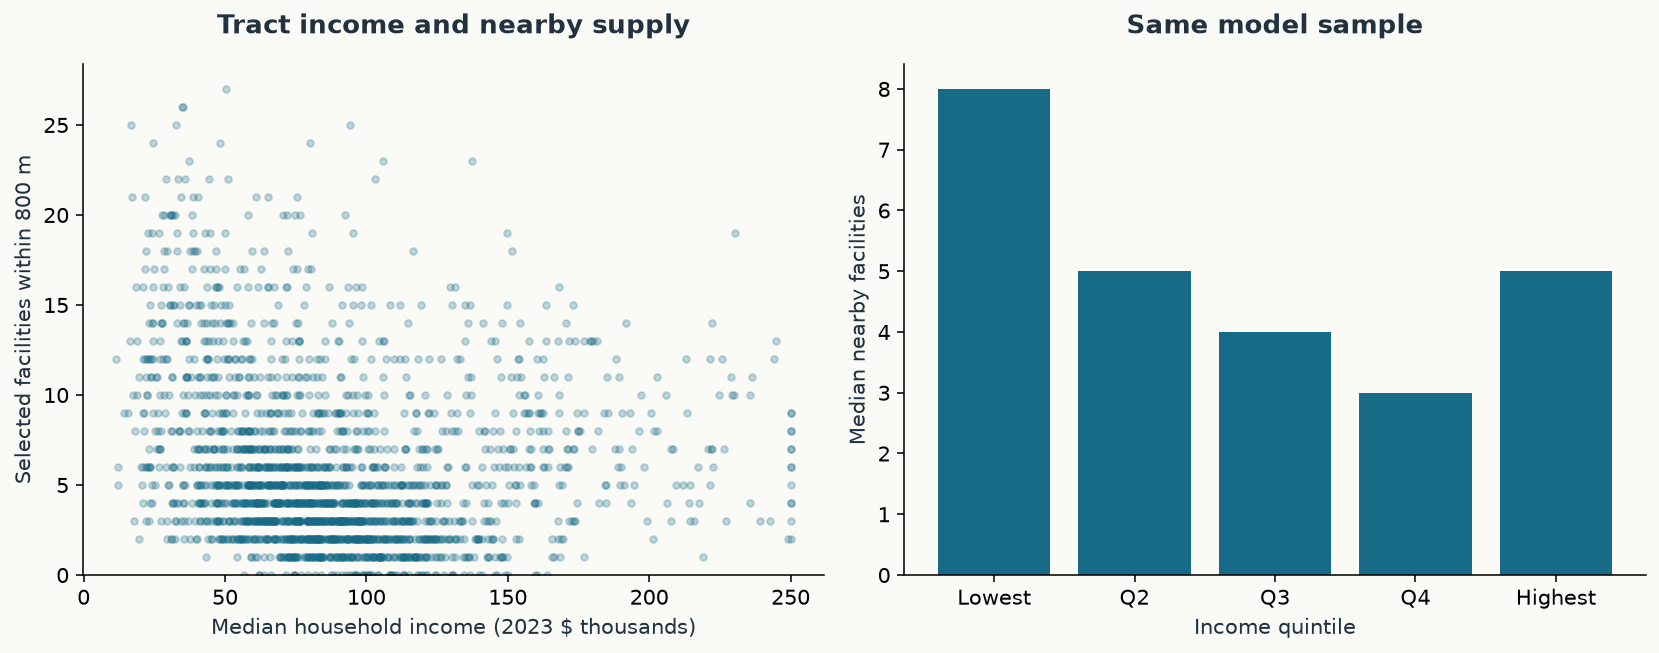

In [4]:
figure, axes = plt.subplots(1, 2, figsize=(12, 4.8))
axes[0].scatter(sample.income / 1000, sample.nearby_800m, s=12, alpha=0.25)
axes[0].set(xlabel="Median household income (2023 $ thousands)", ylabel="Selected facilities within 800 m",
            title="Tract income and nearby supply", ylim=(0, None))
axes[1].bar(quintiles.income_quintile, quintiles.median_nearby)
axes[1].set(xlabel="Income quintile", ylabel="Median nearby facilities", title="Same model sample", ylim=(0, None))
figure.tight_layout()
show_figure(figure)
plt.close(figure)

### Saved chart, diagnostics, correlation, covariance, and VIF

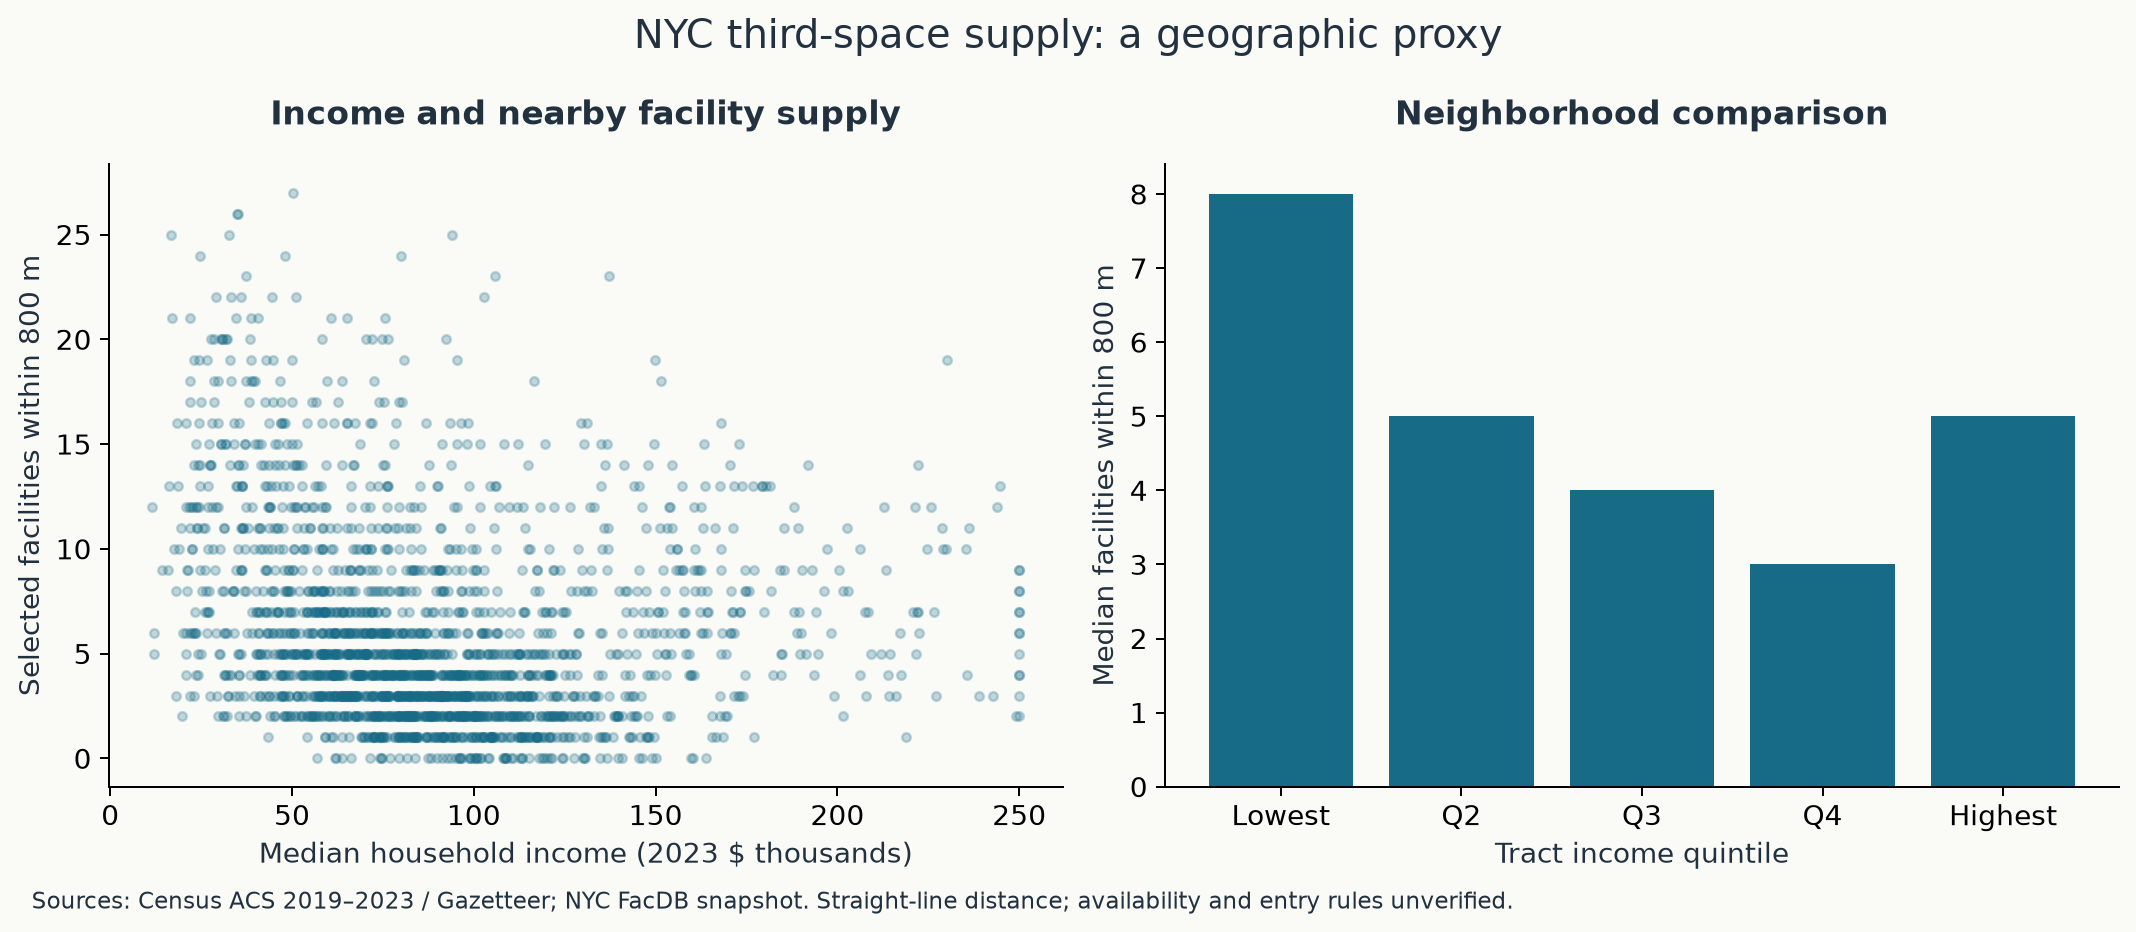

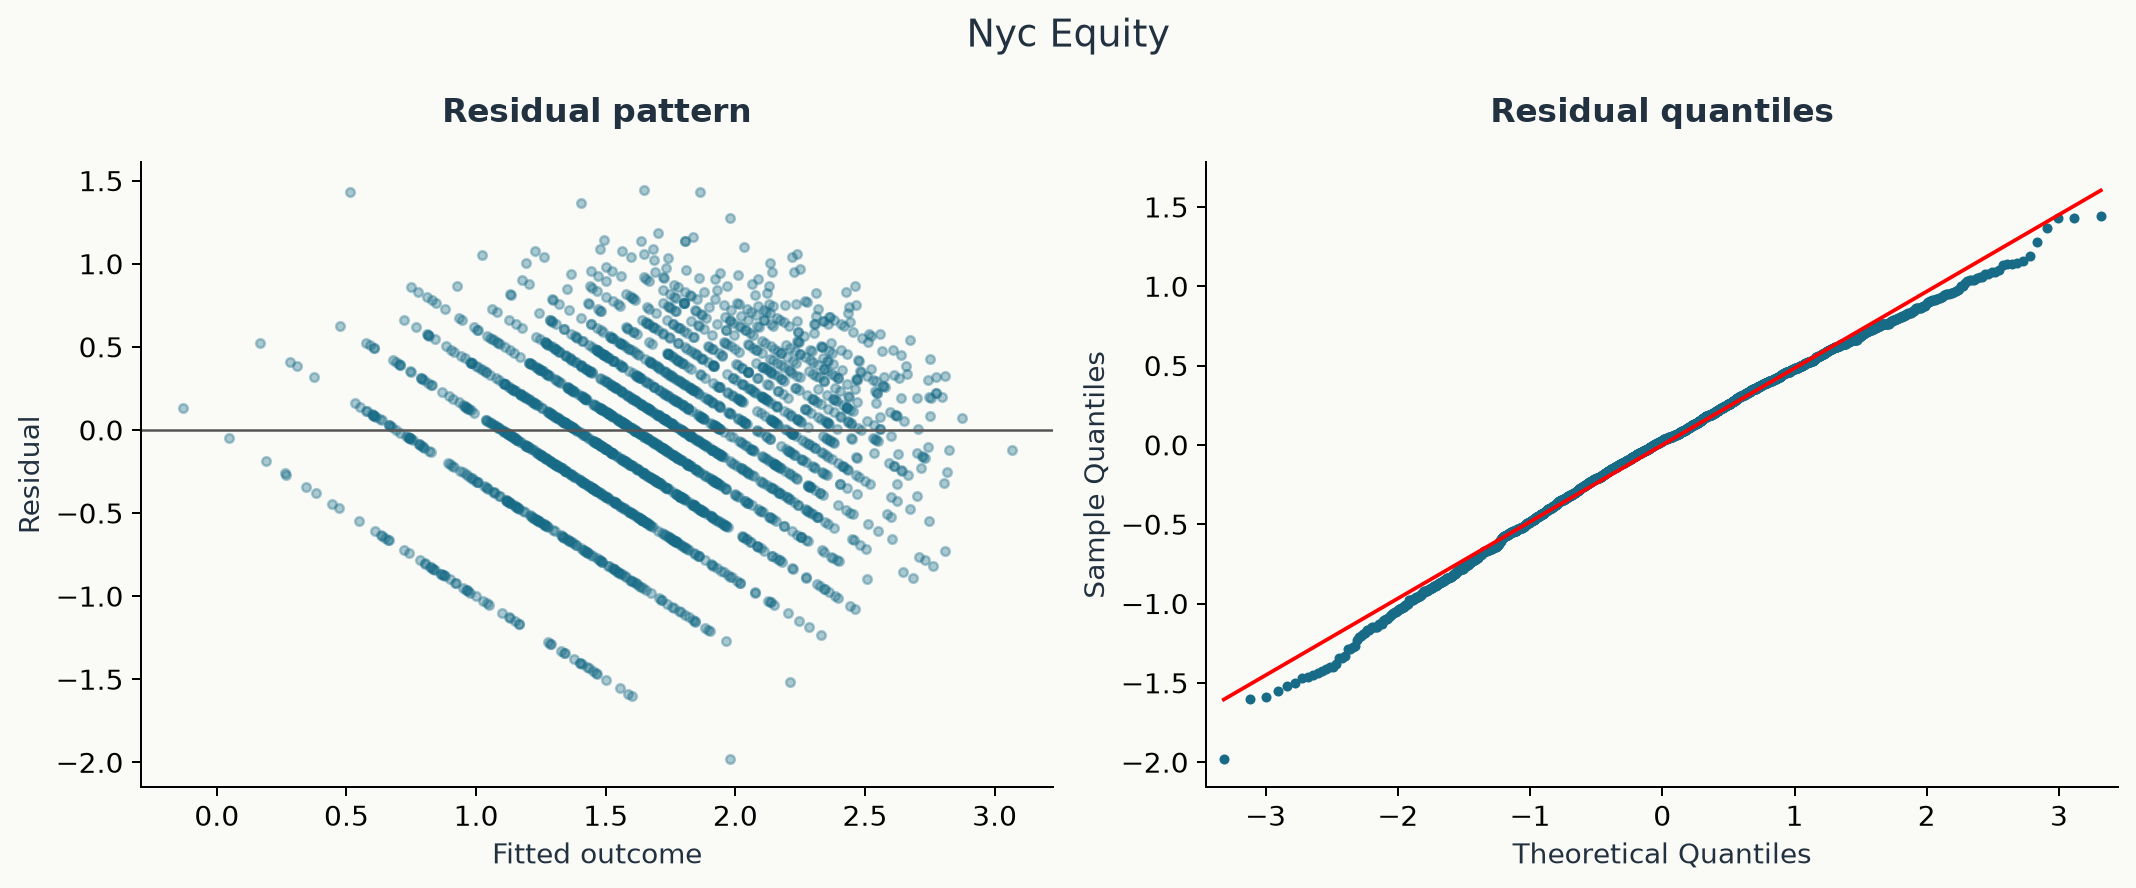

,n,r_squared,condition_number,covariance,design_rank,design_columns,breusch_pagan_p
0,2190,0.4874,1506.1363,HC3,10,10,1.5231e-05


,term,vif
0,Intercept,2347.4925
1,C(borough)[T.Brooklyn],2.3838
2,C(borough)[T.Manhattan],2.1563
3,C(borough)[T.Queens],2.5331
4,C(borough)[T.Staten Island],1.5857
5,log_income,3.0905
6,poverty_pct,3.0714
7,youth_pct,1.1674
8,older_pct,1.2704
9,log_density,1.5990


,variable,log_access,log_income,poverty_pct,youth_pct,older_pct,log_density
0,log_access,1.0000,-0.2696,0.4099,0.0764,-0.2227,0.5728
1,log_income,-0.2696,1.0000,-0.7778,-0.2028,0.0538,-0.1951
2,poverty_pct,0.4099,-0.7778,1.0000,0.2534,-0.2105,0.2735
3,youth_pct,0.0764,-0.2028,0.2534,1.0000,-0.3033,0.0564
4,older_pct,-0.2227,0.0538,-0.2105,-0.3033,1.0000,-0.2058
5,log_density,0.5728,-0.1951,0.2735,0.0564,-0.2058,1.0000


,variable,log_access,log_income,poverty_pct,youth_pct,older_pct,log_density
0,log_access,0.4570,-0.0904,3.2072,0.2837,-1.1551,0.2917
1,log_income,-0.0904,0.2457,-4.4618,-0.5520,0.2044,-0.0728
2,poverty_pct,3.2072,-4.4618,133.9381,16.1015,-18.6843,2.3847
3,youth_pct,0.2837,-0.5520,16.1015,30.1354,-12.7736,0.2333
4,older_pct,-1.1551,0.2044,-18.6843,-12.7736,58.8450,-1.1895
5,log_density,0.2917,-0.0728,2.3847,0.2333,-1.1895,0.5676


In [5]:
show_png("nyc_access_equity")
show_png("nyc_equity_diagnostics")
display(pd.DataFrame([read_json("outputs/qa/nyc_equity_diagnostics.json")]))
display(read_csv("outputs/tables/nyc_equity_vif.csv"))
display(read_csv("outputs/tables/nyc_equity_correlation.csv"))
display(read_csv("outputs/tables/nyc_equity_covariance.csv"))

### Inspect the shared implementation

In [6]:
show_source("econhack.nyc", ["nearby_counts", "equity"])

Source: `src/econhack/nyc.py`. Functions below are displayed, not invoked.

def nearby_counts(tracts, facilities, distance_m):
    valid = facilities[facilities.valid_coordinate]
    if valid.empty:
        raise ValueError("No valid facility coordinates")
    tree = cKDTree(sphere_coordinates(valid.latitude, valid.longitude))
    radius = 2 * np.sin(distance_m / (2 * 6371008.8))
    return tree.query_ball_point(sphere_coordinates(tracts.INTPTLAT, tracts.INTPTLONG), radius, return_length=True)

def equity(frame):
    predictors = ["log_income", "poverty_pct", "youth_pct", "older_pct", "log_density"]
    sample = model_sample(frame, predictors + ["log_access"], "nyc_equity")
    formula = "log_access ~ log_income + poverty_pct + youth_pct + older_pct + log_density + C(borough)"
    model = smf.ols(formula, data=sample).fit(cov_type="HC3")
    regression_outputs(model, "nyc_equity", sample, ["log_access"] + predictors)
    spatial_sensitivity(sample, formula, "nyc_equity")
    sensitivity = []
    for distance in [400, 800, 1200]:
        altered = sample.assign(log_access=np.log1p(sample[f"nearby_{distance}m"]))
        fitted = smf.ols(formula, data=altered).fit(cov_type="HC3")
        for variable in predictors:
            sensitivity.append({"radius_m": distance, "term": variable, "coefficient": fitted.params[variable],
                                "ci_lower": fitted.conf_int().loc[variable, 0], "ci_upper": fitted.conf_int().loc[variable, 1]})
    save_table(pd.DataFrame(sensitivity), "nyc_equity_radius_sensitivity")
    sample["income_quintile"] = pd.qcut(sample.income, 5, labels=["Lowest", "Q2", "Q3", "Q4", "Highest"])
    summary = sample.groupby("income_quintile", observed=True).agg(tracts=("geoid", "size"), median_nearby=("nearby_800m", "median"), mean_nearby=("nearby_800m", "mean"))
    save_table(summary.reset_index(), "nyc_equity_income_quintiles")
    figure, axes = plt.subplots(1, 2, figsize=(12, 5))
    axes[0].scatter(sample.income / 1000, sample.nearby_800m, s=12, alpha=.25)
    axes[0].set(xlabel="Median household income (2023 $ thousands)", ylabel="Selected facilities within 800 m", title="Income and nearby facility supply")
    axes[1].bar(summary.index.astype(str), summary.median_nearby)
    axes[1].set(xlabel="Tract income quintile", ylabel="Median facilities within 800 m", title="Neighborhood comparison")
    figure.suptitle("NYC third-space supply: a geographic proxy", fontsize=16)
    figure.text(.02, -.01, "Sources: Census ACS 2019–2023 / Gazetteer; NYC FacDB snapshot. Straight-line distance; availability and entry rules unverified.", fontsize=9)
    figure.tight_layout()
    save_figure(figure, "nyc_access_equity")
    record_status("nyc_equity", "estimated", "Exploratory tract association; HC3 intervals do not correct spatial dependence or ACS sampling error.", n=len(sample), formula=formula)

## Interpretation and limits

The selected-facility measure describes geographic supply, not verified opening hours, entry eligibility, walking routes, quality, or actual use. HC3 does not correct spatial dependence or ACS sampling uncertainty. Income associations are conditional and observational; facilities and tracts are not randomly assigned.

## Inputs used

Exact local inputs and SHA-256 hashes for this execution. These receipts identify table/figure versions; they are not an independent validation of their statistical content.

In [7]:
display(pd.DataFrame(input_receipts).drop_duplicates().reset_index(drop=True))

,path,sha256
0,data/processed/nyc_access.csv,dc4074b06a30882187ea6e042d7b4499e978d9dfe8259f...
1,data/processed/nyc_selected_facilities.csv,769baebf371c0abfb74988553a8adb29a357a42598d6e2...
2,outputs/model_status.json,1c0591b04c884482be94eb86e682158fbfd08cc0a5f4fc...
3,outputs/tables/nyc_equity_coefficients.csv,6503db9db6994d989ef67ac7b408864b9272408f88be1f...
4,outputs/tables/nyc_equity_income_quintiles.csv,6e79e1ee596372920eeeb2785c24e28b145febaa8bfe67...
5,outputs/tables/nyc_equity_radius_sensitivity.csv,4ac4e50891ce373ca36e710f60f1b666104df28d4bcae6...
6,outputs/figures/nyc_access_equity.png,cf60cfd88d6daf579baa27a2e4dbf162296f750a5b8872...
7,outputs/figures/nyc_equity_diagnostics.png,11c46d551a86e59337a900dd261d72c9fbb9b6f3be118a...
8,outputs/qa/nyc_equity_diagnostics.json,e5503e940db16ba71c0a2c80bdd60c296bb47ef6393cc2...
9,outputs/tables/nyc_equity_vif.csv,73253932f93e1bdf9b9d82d4586ff3029351e3e9403f74...
